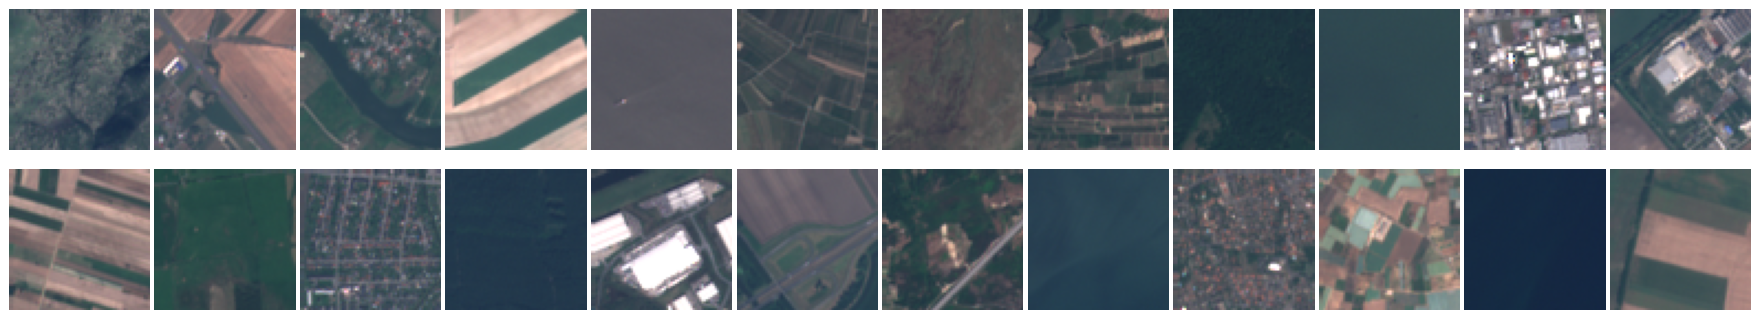

<font size=10>**Proyecto Semana 3**</font>

<font size=6>**Las métricas que no se dejan engañar**</font>

# **Problema de negocio - Un solo número no cuenta la historia**

La semana pasada entrenaste una red que acierta **92 de cada 100** imágenes. **Paola** lo presume en la junta y alguien pregunta: *"perfecto, ¿la ponemos en la app de Smartgrow?"*

Y ahí Paola duda. Porque 92% es un promedio, y los promedios esconden cosas: ¿92% en TODAS las clases, o 99% en bosques y 60% en cultivos permanentes (justo lo que le importa a Smartgrow)? ¿Y si el modelo confunde carreteras con ríos, da lo mismo que si confunde un huerto con un maizal?

Hoy vas a aprender a hacerle a cualquier modelo las tres preguntas que el accuracy no responde: **¿dónde te equivocas?, ¿a quién ignoras?, ¿tu examen fue justo?**

### **El caso de estudio**

1. **Re-entrenar al sospechoso** - el modelo de la semana 2, ahora como acusado.
2. **La trampa del accuracy** - vas a construir un modelo tramposo con 95% de accuracy que es completamente inútil.
3. **El mapa de errores** - la matriz de confusión: ver TODOS los errores de golpe.
4. **Tres métricas nuevas** - precision, recall y F1, calculadas por ti y validadas contra scikit-learn.
5. **El examen justo** - por qué el split de EuroSAT es 60/20/20 y qué es la fuga espacial.

**Tu ruta en este notebook:**

1. **Preparar el entorno** - GPU recomendada (el entrenamiento es corto).
2. **Elegir el modo** - completo (entrega) o rápido (pruebas).
3. **Entrenar el modelo** - el código te lo regalamos: hoy el tema es medir, no entrenar.
4. **Apuesta y trampa** - el modelo tramposo del 95%.
5. **Matriz de confusión** - la construyes tú, celda por celda.
6. **Precision, recall y F1** - tus fórmulas contra scikit-learn.
7. **La clase más difícil** - segunda apuesta y galería de errores.
8. **El examen justo** - splits y fuga espacial.
9. **El veredicto** - resumen y recomendación para Smartgrow.

### **Objetivo**

Al terminar vas a poder:

1. **Construir** una matriz de confusión desde cero y leerla como un mapa de errores.
2. **Calcular** precision, recall, F1 y F1 macro con tus propias fórmulas.
3. **Validar** tus cálculos contra scikit-learn (la librería estándar de la industria).
4. **Explicar** por qué un split mal hecho hace trampa aunque nadie quiera hacer trampa.

**Tiempo estimado:** 2 a 3 horas. Registra tus horas en `hours.csv` con link a tu commit.

# **Preparación del entorno**

**¿Qué hay que hacer?**

- Abre este notebook en **Google Colab**.
- Activa la GPU: menú **Entorno de ejecución**, **Cambiar tipo de entorno de ejecución**, elige **T4 GPU** y guarda. Hoy el entrenamiento es corto, pero con GPU tarda 3 minutos en vez de 30.
- Ejecuta las celdas en orden, de arriba hacia abajo.

In [ ]:
# @title Instalar TorchGeo (2 a 3 minutos; es normal ver mucho texto)
!pip install -q torchgeo

In [ ]:
# @title Importar librerías y verificar la GPU
import torch, torchgeo, numpy as np, matplotlib.pyplot as plt
import torch.nn as nn
from tqdm.auto import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torchgeo:", torchgeo.__version__)
print("Dispositivo:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Hoy también usamos scikit-learn, que ya viene instalado en Colab:")
import sklearn
print("scikit-learn:", sklearn.__version__)

<font color='blue' size="5">**Sample Output Example**</font>

```
torchgeo: 0.8.1
Dispositivo: cuda
GPU: Tesla T4
Hoy también usamos scikit-learn, que ya viene instalado en Colab:
scikit-learn: 1.6.1
```

- La siguiente celda define `verificar()`, el corrector automático (igual que las semanas 1 y 2).
- Va guardando tus resultados para la autocalificación final. **Ejecútala y no la modifiques.**

In [ ]:
# @title Función de autoverificación (ejecutar, no modificar)
REGISTRO = {}

def verificar(nombre, obtenido, esperado, tol=0.0):
    try:
        if obtenido is None:
            print(f"PENDIENTE| {nombre}: aún no completas el TODO de arriba")
            REGISTRO[nombre] = False
            return False
        if isinstance(esperado, (int, float)) and not isinstance(esperado, bool):
            ok = abs(float(obtenido) - float(esperado)) <= tol
        else:
            ok = (obtenido == esperado)
    except Exception as e:
        print(f"REVISA   | {nombre}: tu valor dio error ({e})")
        REGISTRO[nombre] = False
        return False
    print((f"OK       | {nombre}: {obtenido}") if ok else
          (f"REVISA   | {nombre}: obtuviste {obtenido}, se esperaba {esperado}"))
    REGISTRO[nombre] = ok
    return ok

def logro(texto):
    print()
    print("=" * 56)
    print(f"  LOGRO DESBLOQUEADO: {texto}")
    print("=" * 56)

print("Corrector automático listo.")

# **Elige tu modo de juego**

Igual que la semana pasada: **elige en el menú desplegable de la derecha**.

- **completo**: el oficial, el de tu entrega. Necesita GPU.
- **rápido**: miniatura para probar que todo corre. NO es válido para entregar.

In [ ]:
# @title Modo de juego (elige en el menú de la derecha)
MODO = "completo"  # @param ["completo", "rapido"]

if MODO == "completo":
    CFG = {"n_train": 8000, "n_val": 2700, "epochs": 4, "batch": 128, "acc_min": 0.85}
else:
    CFG = {"n_train": 1000, "n_val": 400, "epochs": 4, "batch": 64, "acc_min": 0.60}

print(f"Modo {MODO}: {CFG['n_train']} imágenes de entrenamiento, {CFG['n_val']} de validación.")
if MODO == "completo" and device != "cuda":
    print("OJO: estás en modo completo SIN GPU. Va a tardar muchísimo. Activa la GPU o cambia a rápido para probar.")

# **Paso 1: Re-entrenar al sospechoso**

### **Background**

Para juzgar a un modelo primero hay que tenerlo. Estas celdas reconstruyen el modelo de la semana 2 (ResNet-18 preentrenada + transfer learning). **El código viene completo y ya lo conoces: hoy no se juzga cómo entrena, se juzga cómo se equivoca.**

In [ ]:
# @title Descargar EuroSAT completo (si ya lo tienes de la semana 2, tarda segundos)
from torchgeo.datasets import EuroSAT

full_train = EuroSAT(root="data_full", split="train", download=True)
full_val   = EuroSAT(root="data_full", split="val",   download=True)
print("train:", len(full_train), "| val:", len(full_val))

In [ ]:
# @title Convertir imágenes y entrenar (3 a 5 minutos en GPU)
from torchvision.models import resnet18, ResNet18_Weights

torch.manual_seed(42); np.random.seed(42)
MEDIA = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
DESV  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def a_tensor_rgb(imagen):
    rgb = (imagen[[3, 2, 1], :, :] / 3000.0).clamp(0, 1)
    return (rgb - MEDIA) / DESV

g = torch.Generator().manual_seed(42)
idx_tr = torch.randperm(len(full_train), generator=g)[:CFG["n_train"]]
idx_va = torch.randperm(len(full_val),   generator=g)[:CFG["n_val"]]
X_train = torch.stack([a_tensor_rgb(full_train[int(i)]["image"]) for i in tqdm(idx_tr, desc="train")])
y_train = torch.tensor([int(full_train[int(i)]["label"]) for i in idx_tr])
X_val   = torch.stack([a_tensor_rgb(full_val[int(i)]["image"]) for i in tqdm(idx_va, desc="val")])
y_val   = torch.tensor([int(full_val[int(i)]["label"]) for i in idx_va])

modelo = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
modelo.fc = nn.Linear(512, 10)
modelo = modelo.to(device)
opt = torch.optim.Adam(modelo.parameters(), lr=3e-4)
fn_perdida = nn.CrossEntropyLoss()
idx = torch.arange(len(X_train))

for epoca in range(CFG["epochs"]):
    modelo.train()
    perm = idx[torch.randperm(len(idx))]
    for i in tqdm(range(0, len(perm), CFG["batch"]), desc=f"época {epoca+1}", leave=False):
        b = perm[i:i+CFG["batch"]]
        opt.zero_grad()
        perdida = fn_perdida(modelo(X_train[b].to(device)), y_train[b].to(device))
        perdida.backward()
        opt.step()
    modelo.eval()
    with torch.no_grad():
        aciertos = 0
        for i in range(0, len(X_val), 256):
            aciertos += int((modelo(X_val[i:i+256].to(device)).argmax(1).cpu() == y_val[i:i+256]).sum())
    print(f"  época {epoca+1}/{CFG['epochs']} | validación {aciertos/len(X_val)*100:.1f}%")

with torch.no_grad():
    preds = torch.cat([modelo(X_val[i:i+256].to(device)).argmax(1).cpu()
                       for i in range(0, len(X_val), 256)])
CLASES = full_val.classes
print("\nListo. El sospechoso está en la sala de interrogatorios.")

In [ ]:
# @title Verificación
acc_global = float((preds == y_val).float().mean())
verificar("el modelo aprendió (supera el mínimo de tu modo)", bool(acc_global >= CFG["acc_min"]), True)
verificar("hay una predicción por imagen de validación", len(preds), CFG["n_val"])
print(f"\nAccuracy global: {acc_global*100:.1f}%  <- este es el número que Paola presume en la junta")

<font color='blue' size="5">**Sample Output Example**</font>

```
OK       | el modelo aprendió (supera el mínimo de tu modo): True
OK       | hay una predicción por imagen de validación: 400

Accuracy global: 92.0%  <- este es el número que Paola presume en la junta
```
(Ejemplo de una corrida en modo rápido. En modo completo el accuracy sube un poco y se evalúa con 2,700 imágenes.)

# **Tarea 1: La apuesta y la trampa del 95%**

**Note:** sigue las instrucciones con cuidado y completa las secciones faltantes.

Antes de desconfiar del accuracy, hay que verlo fallar en vivo. Vamos a construir el modelo más tonto del mundo y a ver cuánto "acierta".

#### **TASK**

1. **Mueve el deslizador**: imagina un detector de plagas donde 95 de cada 100 parcelas están sanas. Un "modelo" que SIEMPRE dice "sana", ¿qué accuracy crees que saque?
2. Ejecuta las dos celdas siguientes y compara.

In [ ]:
# @title Mi apuesta (mueve el deslizador)
MI_APUESTA_TRAMPOSO = 95  # @param {type:"slider", min:0, max:100, step:5}
print(f"Apostaste que el modelo tramposo saca {MI_APUESTA_TRAMPOSO} de 100. Veamos...")

In [ ]:
# @title El modelo tramposo: SIEMPRE dice "sana"
# Escenario: un valle con 100 parcelas: 95 sanas y 5 con plaga
y_escenario = ["sana"] * 95 + ["plaga"] * 5

pred_tramposo = ["sana"] * len(y_escenario)   # el "modelo": siempre la clase mayoritaria

acc_tramposo = sum(1 for real, p in zip(y_escenario, pred_tramposo) if real == p) / len(y_escenario)
plagas_detectadas = sum(1 for real, p in zip(y_escenario, pred_tramposo) if real == "plaga" and p == "plaga")

print(f"Accuracy del modelo tramposo: {acc_tramposo*100:.0f}%")
print(f"Tu apuesta:                   {MI_APUESTA_TRAMPOSO}%")
print(f"Plagas detectadas:            {plagas_detectadas} de 5")
if abs(acc_tramposo*100 - MI_APUESTA_TRAMPOSO) <= 5:
    logro("OJO DE ÁGUILA - viste venir la trampa")
print("\n95% de accuracy... y detectó exactamente CERO plagas. Que era lo único que importaba.")

In [ ]:
# @title Verificación
verificar("accuracy del tramposo (engañosamente alto)", round(acc_tramposo, 2), 0.95)
verificar("plagas que detectó el tramposo", plagas_detectadas, 0)

In [ ]:
# @title Análisis adicional de la trampa: el porcentaje no es utilidad
from sklearn.metrics import recall_score, f1_score
recall_plaga = recall_score(y_escenario, pred_tramposo, pos_label="plaga", zero_division=0)
f1_macro_tramposo = f1_score(y_escenario, pred_tramposo,
                             labels=["sana", "plaga"], average="macro", zero_division=0)
print(f"Accuracy de un clasificador que siempre dice 'sana': {acc_tramposo:.1%}")
print(f"Recall de la clase crítica ('plaga'): {recall_plaga:.1%}")
print(f"F1 macro con ambas clases: {f1_macro_tramposo:.1%}")
print("Decisión: rechazarlo como detector de plagas, aunque tenga accuracy elevado.")


<font color='blue' size="5">**Sample Output Example**</font>

```
Accuracy del modelo tramposo: 95%
Plagas detectadas:            0 de 5
```
**Moraleja:** cuando las clases están desbalanceadas, el accuracy premia al que apuesta todo a la clase grande. Por eso existen las métricas de hoy.

# **Tarea 2: El mapa de errores (matriz de confusión)**

**Note:** sigue las instrucciones con cuidado y completa las secciones faltantes.

La matriz de confusión es una tabla de 10 x 10: cada **fila** es lo que la imagen ERA en realidad, cada **columna** es lo que el modelo DIJO. Cada imagen suma 1 en una casilla:

- Si era `Forest` y dijo `Forest`, suma en la diagonal. Acierto.
- Si era `Highway` y dijo `River`, suma fuera de la diagonal. Error, y la casilla te dice CUÁL error.

#### **TASK**

Completa los dos `None`: en qué **fila** y en qué **columna** se suma cada imagen.

1. La fila es la clase **real** de la imagen.
2. La columna es la clase que el modelo **predijo**.

In [ ]:
# @title TU CÓDIGO - completa los dos None
cm = np.zeros((10, 10), dtype=int)

for real, pred in zip(y_val.numpy(), preds.numpy()):
    fila    = int(real)   # Filas: referencia (ground truth)
    columna = int(pred)  # Columnas: salida del modelo
    if fila is None or columna is None:
        print("Aún no completas los TODO.")
        break
    cm[fila, columna] += 1
else:
    print("Matriz construida. Total de imágenes contadas:", cm.sum())

In [ ]:
# @title Verificación
verificar("la matriz cuenta todas las imágenes",
          None if cm.sum() == 0 else int(cm.sum()), CFG["n_val"])
verificar("la diagonal son los aciertos",
          None if cm.sum() == 0 else int(np.diag(cm).sum()), int((preds == y_val).sum()))

In [ ]:
# @title Dibujar el mapa de errores
fig, ax = plt.subplots(figsize=(9, 7.2))
ax.imshow(cm, cmap="Greens")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(CLASES, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(CLASES, fontsize=9)
for i in range(10):
    for j in range(10):
        if cm[i, j] > 0:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9, fontweight="bold",
                    color=("white" if cm[i, j] > cm.max() * 0.6 else "#403A39"))
ax.set_xlabel("Lo que dijo el modelo", fontweight="bold")
ax.set_ylabel("Lo que era en realidad", fontweight="bold")
ax.set_title("Tu matriz de confusión", fontweight="bold")
plt.tight_layout(); plt.show()
print("Lee la matriz como detective: busca el número más grande FUERA de la diagonal.")

<font color='blue' size="5">**Sample Output Example**</font>

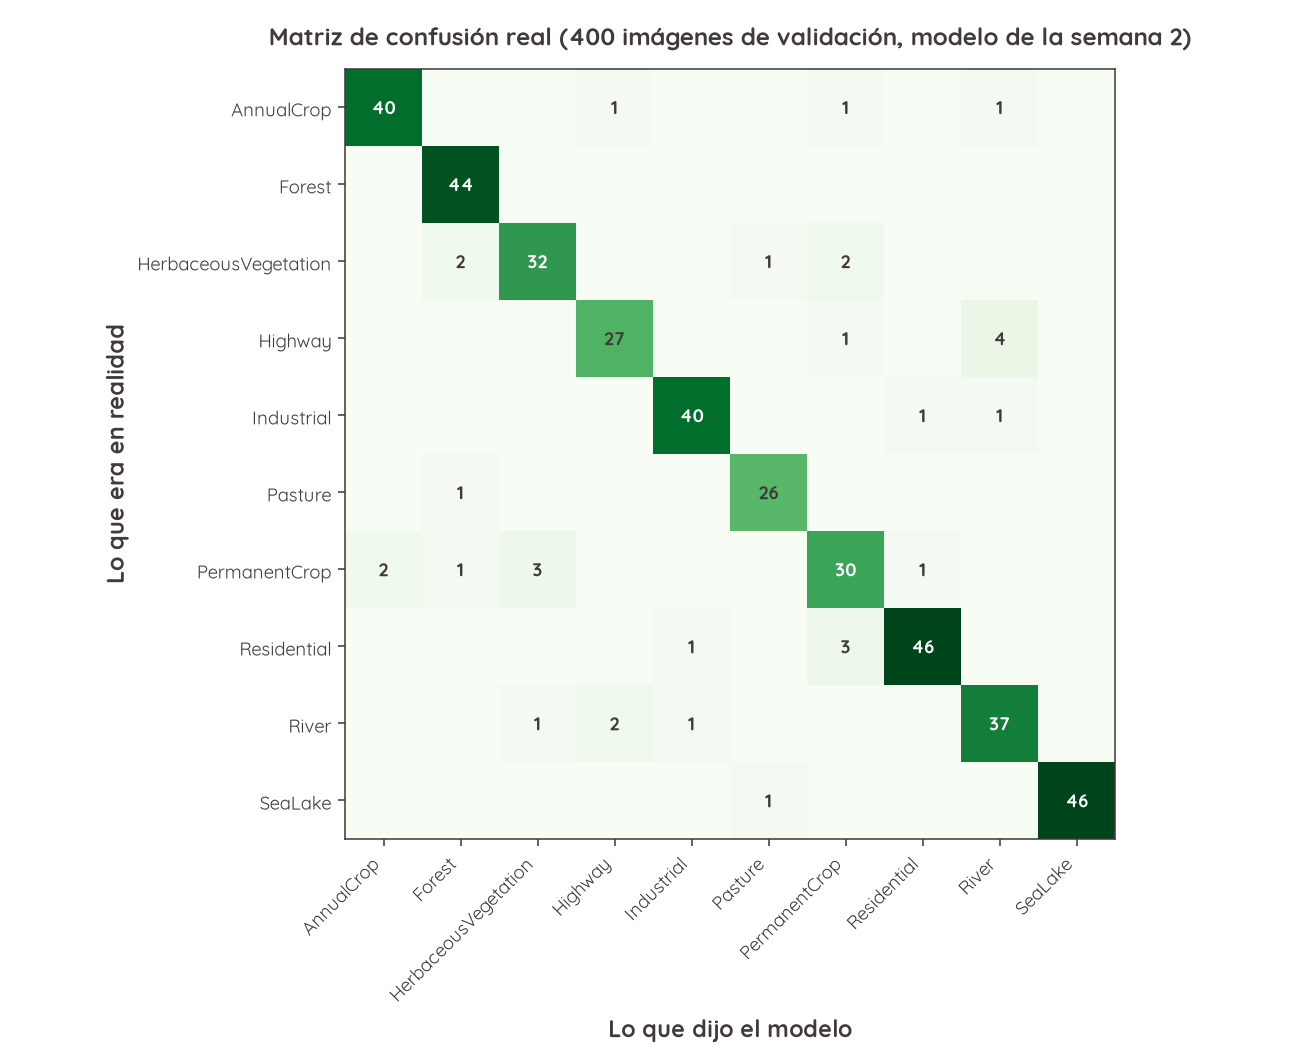

(Ejemplo de una corrida en modo rápido: la diagonal verde oscuro son los aciertos; el error más repetido fue confundir `Highway` con `River`: vistas desde 640 metros de altura, una carretera y un río son dos líneas delgadas que cruzan el paisaje.)

# **Tarea 3: Precision, recall y F1**

**Note:** sigue las instrucciones con cuidado y completa las secciones faltantes.

De la matriz salen las tres métricas de hoy. Para una clase (piensa en una alarma de incendios):

- **Precision** = "cuando doy la alarma, ¿es cierto?" -> aciertos de la clase / veces que el modelo **dijo** esa clase (su **columna**).
- **Recall** = "de los incendios reales, ¿cuántos detecté?" -> aciertos de la clase / veces que la clase **era** en realidad (su **fila**).
- **F1** = el promedio armónico de las dos: solo es alto si las DOS son decentes.

#### **TASK**

Completa los tres `None` con las fórmulas. Ya tienes los ingredientes calculados:

1. `precision` = aciertos_por_clase / predichos_por_clase
2. `recall` = aciertos_por_clase / reales_por_clase
3. `f1` = 2 * precision * recall / (precision + recall)

In [ ]:
# @title TU CÓDIGO - completa los tres None
aciertos_por_clase  = np.diag(cm)                        # la diagonal
predichos_por_clase = np.maximum(cm.sum(axis=0), 1)      # suma de cada columna (el maximum evita dividir entre 0)
reales_por_clase    = np.maximum(cm.sum(axis=1), 1)      # suma de cada fila

precision = aciertos_por_clase / predichos_por_clase  # TP / (TP + FP)
recall    = aciertos_por_clase / reales_por_clase     # TP / (TP + FN)
f1 = np.divide(2 * precision * recall, precision + recall,
               out=np.zeros_like(precision, dtype=float),
               where=(precision + recall) > 0)  # F1: media armónica, segura ante 0/0

if f1 is not None:
    print(f"{'Clase':<22}{'Precision':>10}{'Recall':>10}{'F1':>10}")
    print("-" * 52)
    for k, nombre in enumerate(CLASES):
        print(f"{nombre:<22}{precision[k]*100:>9.1f}%{recall[k]*100:>9.1f}%{f1[k]*100:>9.1f}%")

In [ ]:
# @title Verificación contra scikit-learn (el estándar de la industria)
from sklearn.metrics import precision_recall_fscore_support

sk_p, sk_r, sk_f1, _ = precision_recall_fscore_support(
    y_val.numpy(), preds.numpy(), labels=range(10), zero_division=0)

verificar("tu precision coincide con scikit-learn",
          None if precision is None else bool(np.allclose(precision, sk_p, atol=1e-6)), True)
verificar("tu recall coincide con scikit-learn",
          None if recall is None else bool(np.allclose(recall, sk_r, atol=1e-6)), True)
verificar("tu F1 coincide con scikit-learn",
          None if f1 is None else bool(np.allclose(f1, sk_f1, atol=1e-6)), True)
if f1 is not None and bool(np.allclose(f1, sk_f1, atol=1e-6)):
    logro("CALCULISTA CERTIFICADO - tus fórmulas dan lo mismo que scikit-learn")

<font color='blue' size="5">**Sample Output Example**</font>

```
OK       | tu precision coincide con scikit-learn: True
OK       | tu recall coincide con scikit-learn: True
OK       | tu F1 coincide con scikit-learn: True

========================================================
  LOGRO DESBLOQUEADO: CALCULISTA CERTIFICADO - tus fórmulas dan lo mismo que scikit-learn
========================================================
```
A partir de hoy puedes usar `sklearn.metrics` con confianza: ya sabes exactamente qué calcula por dentro.

# **Tarea 4: La clase más difícil**

**Note:** sigue las instrucciones con cuidado y completa las secciones faltantes.

El **F1 macro** es el promedio simple de los 10 F1: trata a todas las clases igual, tengan muchas o pocas imágenes. Por eso es la métrica oficial de tu módulo, y no el accuracy.

#### **TASK**

1. **Elige en el menú desplegable**: ¿cuál crees que sea la clase MÁS difícil para el modelo? (Pista de agrónoma: piensa en la semana 1 y en el empate del NDVI.)
2. Completa el `None` del F1 macro.
3. Ejecuta y descubre si le atinaste.

In [ ]:
# @title Mi apuesta: la clase más difícil (elige en el menú de la derecha)
MI_CLASE_DIFICIL = "PermanentCrop"  # @param ["AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial", "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]
print(f"Apostaste que la clase más difícil es {MI_CLASE_DIFICIL}. Veamos...")

In [ ]:
# @title TU CÓDIGO - completa el None
f1_macro = float(f1.mean())  # Promedio sin ponderación por tamaño de clase

if f1_macro is not None:
    peor = int(np.argmin(f1))
    print(f"F1 macro:        {f1_macro*100:.1f}%")
    print(f"Accuracy global: {acc_global*100:.1f}%")
    print(f"\nLa clase más difícil fue: {CLASES[peor]} (F1 {f1[peor]*100:.1f}%)")
    print(f"Tu apuesta:               {MI_CLASE_DIFICIL}")
    if CLASES[peor] == MI_CLASE_DIFICIL:
        logro("DETECTIVE DE CLASES - le atinaste a la más difícil")

In [ ]:
# @title Verificación
from sklearn.metrics import f1_score
verificar("tu F1 macro coincide con scikit-learn",
          None if f1_macro is None else round(float(f1_macro), 4),
          round(float(f1_score(y_val.numpy(), preds.numpy(), average="macro", zero_division=0)), 4),
          tol=1e-3)
verificar("tu accuracy es coherente con tu matriz (diagonal / total)",
          None if cm.sum() == 0 else round(float(np.trace(cm) / cm.sum()), 4),
          round(acc_global, 4), tol=1e-6)

### Lectura técnica de las métricas: evaluar antes de desplegar

Para mí, una métrica no sirve únicamente para celebrar un porcentaje; debe permitir **decidir qué mejorar, qué validar y qué riesgos todavía no comprendemos**. Por eso distingo tres niveles:

- **Calidad global:** `accuracy` resume los aciertos por imagen, mientras `F1 macro` concede el mismo peso a cada categoría, incluso si cambia su frecuencia.
- **Calidad por clase:** la matriz revela *qué* se está confundiendo; `recall` identifica omisiones y `precision` alerta sobre clasificaciones positivas incorrectas. Las cantidades y los porcentajes no deben mezclarse: una confusión frecuente en números absolutos no es necesariamente la de mayor tasa.
- **Validez operacional:** un resultado de validación no demuestra por sí solo generalización a nuevas zonas, estaciones o sensores. No propondría una decisión automática de alto impacto sin una prueba geográfica independiente.

**Hipótesis previa (Tarea 4):** seleccioné `PermanentCrop` como posible clase difícil porque cultivos permanentes y otras coberturas vegetales pueden tener apariencia RGB parecida en recortes pequeños. Es una hipótesis, **no una conclusión**: la clase realmente peor se calcula con `argmin(f1)` y puede resultar distinta en cada entrenamiento.


In [ ]:
# @title Diagnóstico adicional: distribución de errores y clases prioritarias
# Misma matriz de la Tarea 2. No sustituye ninguna de las 15 verificaciones.
soporte = cm.sum(axis=1)
cm_por_clase = np.divide(cm, soporte[:, None],
                         out=np.zeros_like(cm, dtype=float),
                         where=soporte[:, None] > 0)

matriz_errores = cm.copy()
np.fill_diagonal(matriz_errores, 0)
real_fallo, pred_fallo = np.unravel_index(np.argmax(matriz_errores), matriz_errores.shape)
fallos_max = int(matriz_errores[real_fallo, pred_fallo])

fig, ax = plt.subplots(figsize=(9.5, 7.5))
im = ax.imshow(cm_por_clase * 100, cmap="YlOrRd", vmin=0, vmax=100)
ax.set_xticks(np.arange(len(CLASES)), labels=CLASES, rotation=50, ha="right")
ax.set_yticks(np.arange(len(CLASES)), labels=CLASES)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title("Errores por clase real (porcentaje de cada fila)")
fig.colorbar(im, ax=ax, label="% de imágenes de esa clase")
plt.tight_layout()
plt.show()

print(f"Clase con menor F1: {CLASES[int(np.argmin(f1))]} (F1={f1.min():.3f}; n={soporte[int(np.argmin(f1))]})")
if fallos_max > 0:
    print(f"Confusión dirigida más frecuente: {CLASES[real_fallo]} → {CLASES[pred_fallo]} "
          f"({fallos_max} imágenes de {int(soporte[real_fallo])} de esa clase real)")
else:
    print("No se registraron errores fuera de la diagonal en esta validación.")
print(f"Errores totales de clasificación: {int(matriz_errores.sum())} de {len(y_val)}")

# Importante: los conteos absolutos no equivalen a tasas de error si el soporte cambia.
# La matriz normalizada evita interpretar más ejemplos observados como peor desempeño.


<font color='blue' size="5">**Sample Output Example**</font>

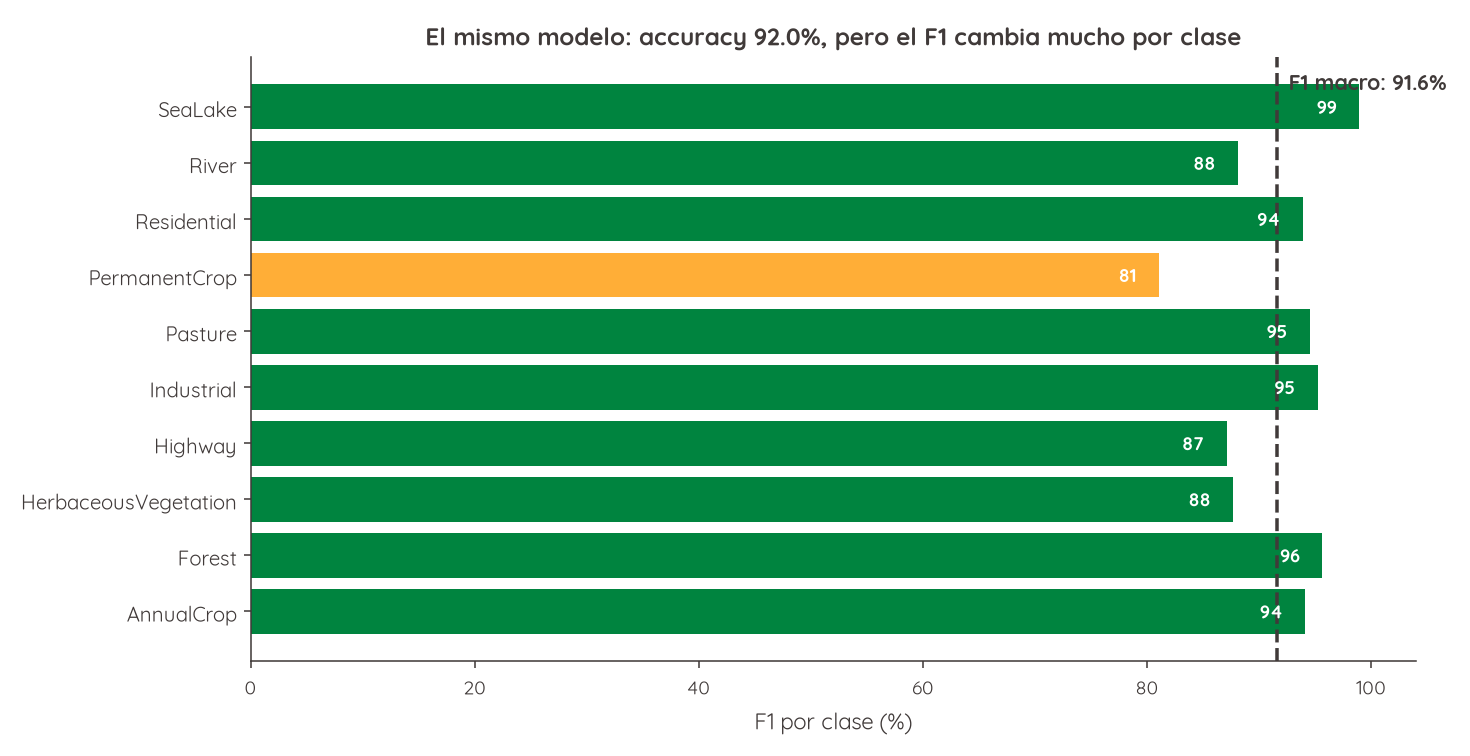

(Corrida de ejemplo en modo rápido: accuracy 92.0% pero el F1 va de 81% a 99% según la clase. La más difícil fue `PermanentCrop`, el huerto: justo la clase que el NDVI tampoco podía separar en la semana 1, y justo la que más le importa a Smartgrow.)

# **Tarea 5: La galería de errores**

Un buen equipo de ML no solo mide sus errores: **los mira a los ojos**. Mueve el deslizador para recorrer las imágenes donde tu modelo se equivocó y ejecuta la celda cada vez. ¿Le habrías atinado tú?

In [ ]:
# @title Recorre los errores (mueve el deslizador y ejecuta)
ERROR_N = 31  # @param {type:"slider", min:0, max:31, step:1}

errores = [i for i in range(len(y_val)) if int(preds[i]) != int(y_val[i])]
i = errores[int(ERROR_N) % len(errores)]

vis = full_val[int(idx_va[i])]["image"]
rgb = (vis[[3, 2, 1], :, :] / 3000.0).clamp(0, 1).permute(1, 2, 0).numpy()
plt.figure(figsize=(4.2, 4.2))
plt.imshow(rgb); plt.axis("off")
plt.title(f"el modelo dijo: {CLASES[int(preds[i])]}\nen realidad era: {CLASES[int(y_val[i])]}",
          color="#B8641B", fontweight="bold")
plt.show()
print(f"Error {int(ERROR_N) % len(errores) + 1} de {len(errores)}. ¿Tú qué habrías dicho?")

# **Tarea 6: El examen justo (train, val y test)**

**Note:** sigue las instrucciones con cuidado y completa las secciones faltantes.

Todas las métricas de hoy valen **cero** si el examen no fue justo. EuroSAT ya viene partido en tres grupos que no comparten NI UNA imagen:

- **train**: para aprender (la red SÍ ve las respuestas).
- **val**: para decidir configuraciones (se consulta, no se aprende).
- **test**: el examen final. Se toca UNA vez, al final del proyecto.

#### **TASK**

Completa el `None`: ¿qué porcentaje del dataset es train?

In [ ]:
# @title Los tres grupos y TU CÓDIGO - completa el None
full_test = EuroSAT(root="data_full", split="test", download=True)

n_tr, n_va, n_te = len(full_train), len(full_val), len(full_test)
total = n_tr + n_va + n_te
print(f"train: {n_tr} | val: {n_va} | test: {n_te} | total: {total}")

pct_train = n_tr / total * 100  # Porcentaje de entrenamiento sobre el total

if pct_train is not None:
    print(f"El split de EuroSAT es {pct_train:.0f} / {n_va/total*100:.0f} / {n_te/total*100:.0f}")

In [ ]:
# @title Verificación
verificar("tamaño de train", n_tr, 16200)
verificar("tamaño de val", n_va, 5400)
verificar("tamaño de test", n_te, 5400)
verificar("porcentaje de train bien calculado",
          None if pct_train is None else round(float(pct_train), 1), 60.0, tol=0.1)

<font color='blue' size="5">**Sample Output Example**</font>

```
train: 16200 | val: 5400 | test: 5400 | total: 27000
El split de EuroSAT es 60 / 20 / 20
```

### **La fuga espacial: la trampa que nadie quiere hacer**

Hay una trampa que pasa aunque nadie la busque. Dos parcelas vecinas son **casi gemelas**: mismo suelo, mismo clima, mismo cultivo. Si una cae en train y su vecina en test, el examen final trae las respuestas escondidas: el modelo "acierta" por haber memorizado al vecino, no por entender cultivos.

**Regla para tu módulo en Smartgrow:** los splits se hacen por ZONA GEOGRÁFICA (parcelas completas, regiones completas), nunca por imagen suelta. En la semana 4, cuando armes los datos de tu módulo, esta regla es ley.

### Nota de ingeniería: no basta con que los archivos sean distintos

La separación 60/20/20 evita que el mismo registro aparezca directamente en dos grupos, pero para imágenes geoespaciales el problema adicional es la **autocorrelación espacial**: dos imágenes de zonas vecinas pueden compartir condiciones ambientales. Una evaluación defendible para Smartgrow debería usar identificadores de parcela o polígonos de región para impedir que las mismas zonas se repartan entre entrenamiento y prueba.

Además, reservaría **test para la evaluación final** y reportaría siempre el soporte de cada categoría junto a precision, recall y F1. Una clase con pocos ejemplos tiene métricas más variables: ningún porcentaje debe interpretarse sin el tamaño de la muestra.


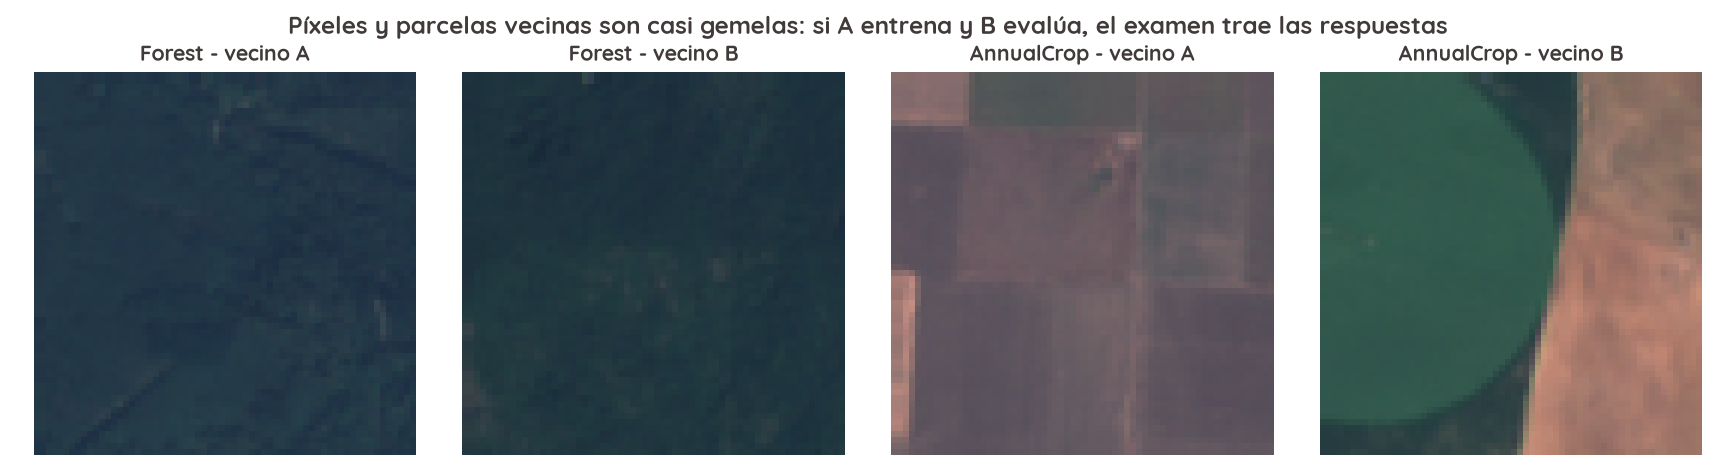

(Imágenes reales de EuroSAT: dos bosques y dos cultivos anuales. Si A entrena y B evalúa, el examen trae las respuestas.)

# **Tarea 7: Evaluación**

**Note:** ejecuta esta celda al final, cuando todo esté completo. **La meta es 15 de 15** (en modo completo, que es el de la entrega).

In [ ]:
# @title Resumen de verificaciones (ejecutar al final)
total = len(REGISTRO)
buenas = sum(1 for v in REGISTRO.values() if v)
print("=" * 56)
print(f"  VERIFICACIONES SUPERADAS: {buenas} de {total}  (meta: 15 de 15)")
print(f"  MODO: {MODO}  (la entrega oficial es en modo completo)")
print("=" * 56)
if total < 15:
    print("\nAún no has ejecutado todas las celdas de verificación.")
pend = [n for n, v in REGISTRO.items() if not v]
if pend:
    print("\nPendientes o incorrectas:")
    for n in pend:
        print("  -", n)
elif total >= 15 and MODO == "completo":
    logro("SEMANA 3 COMPLETA - tus métricas ya no se dejan engañar")

<font color='blue' size="5">**Sample Output Example**</font>

```
========================================================
  VERIFICACIONES SUPERADAS: 15 de 15  (meta: 15 de 15)
  MODO: completo  (la entrega oficial es en modo completo)
========================================================

========================================================
  LOGRO DESBLOQUEADO: SEMANA 3 COMPLETA - tus métricas ya no se dejan engañar
========================================================
```

# **Tarea 8: Resumen y recomendación**

**Note:** sigue las instrucciones con cuidado y completa las secciones faltantes.

Escribe tu **Resumen y Recomendación** para el equipo de Smartgrow. Este texto es la base del **reporte de métricas** que entrega tu equipo esta semana.

**Instructions:**

**1. Los dos números:**

* Accuracy global y F1 macro de tu corrida. ¿Por qué pueden contar historias distintas?

**2. El diagnóstico:**

* ¿Cuál fue la peor clase y cuál fue el error más repetido de la matriz? ¿Tiene lógica agronómica?

**3. La trampa:**

* Con tus palabras: ¿por qué el modelo tramposo del 95% era inútil, y qué métrica lo delata?

**4. Recomendación final:**

* Si Smartgrow solo pudiera vigilar UNA métrica de tu módulo en producción, ¿cuál eliges y por qué?

## Resumen y recomendación — Smartgrow

**1. Mis números y su significado.** El *accuracy* es la proporción total de clasificaciones correctas; el *F1 macro* es el promedio de los F1 de las diez clases sin favorecer a las más numerosas. Ambos pueden parecer cercanos en una validación relativamente balanceada, pero no miden lo mismo. **Los porcentajes de esta corrida, calculados sin inventarlos, aparecen en el informe automático de la siguiente celda**, junto a la diferencia en puntos porcentuales.

**2. Diagnóstico del error.** Me interesa tanto conocer la clase con menor F1 como identificar la *confusión dirigida* más repetida: no es lo mismo clasificar un cultivo anual como permanente que invertir la dirección. La matriz me permite plantear hipótesis sobre semejanza de texturas, coberturas vegetales y resolución espacial. Sin inspeccionar las imágenes y sus metadatos, esas hipótesis no constituyen una causa comprobada.

**3. La trampa del 95 %.** Afirmar que un detector funciona porque acertó 95 de 100 parcelas sería inaceptable si ignoró las cinco con plaga. En ese ejemplo el *recall de plaga es 0 %*: precisamente los cinco casos prioritarios quedaron sin detectar. El ejemplo es binario y pedagógico; **EuroSAT identifica coberturas terrestres, no diagnostica plagas**.

**4. Recomendación para producción.** Si Smartgrow me obligara a vigilar una sola métrica general del clasificador multiclase, escogería **F1 macro**, porque no deja que una clase abundante esconda el deterioro de otras. Sin embargo, para usos agronómicos con costos asimétricos mantendría además una alarma operativa sobre el *recall* de la clase crítica. No basta con una cifra: exigiría validación por región, monitoreo de desplazamiento de datos y revisión humana de predicciones inciertas.

**5. Calidad experimental.** El split 60/20/20 de EuroSAT separa registros entre train, validation y test, pero eso **no demuestra independencia geográfica**. Imágenes vecinas o de una misma zona pueden compartir condiciones y hacer optimista la evaluación. El conjunto de test debe reservarse para el cierre, y una evaluación de Smartgrow con nuevos territorios debe agrupar por parcelas o regiones completas.


In [ ]:
# @title Informe final con los números reales de ESTA corrida (ejecutar después de Tarea 7)
# La redacción de arriba explica nuestro criterio; esta celda inserta la evidencia cuantitativa.
from IPython.display import display, Markdown

peor_idx = int(np.argmin(f1))
matriz_sin_diagonal = cm.copy()
np.fill_diagonal(matriz_sin_diagonal, 0)
fila_err, columna_err = np.unravel_index(np.argmax(matriz_sin_diagonal), matriz_sin_diagonal.shape)
num_confusiones = int(matriz_sin_diagonal[fila_err, columna_err])

if num_confusiones > 0:
    confusión_frecuente = (f"**{CLASES[fila_err]} → {CLASES[columna_err]}**: "
                           f"{num_confusiones} imágenes de las {int(cm[fila_err].sum())} "
                           f"imágenes reales de `{CLASES[fila_err]}` "
                           f"({num_confusiones / max(int(cm[fila_err].sum()), 1):.1%} de esa clase).")
else:
    confusión_frecuente = "No hubo errores fuera de la diagonal."

texto_informe = f"""
### Resultado empírico — {MODO} (validación: {len(y_val):,} imágenes)

1. **Mis números.** Accuracy **{acc_global:.2%}**; F1 macro **{f1_macro:.2%}**;
   diferencia (accuracy − F1 macro): **{(acc_global - f1_macro) * 100:+.2f} puntos porcentuales**.
   El accuracy privilegia el número total de aciertos; el F1 macro representa
   por igual a las diez clases y es más informativo ante cambios en sus frecuencias.
2. **Diagnóstico.** Clase con menor F1: **{CLASES[peor_idx]}**
   (F1 = **{f1[peor_idx]:.2%}**, precision = **{precision[peor_idx]:.2%}**,
   recall = **{recall[peor_idx]:.2%}**; soporte: **{int(cm[peor_idx].sum())}** imágenes).
   Confusión dirigida más repetida: {confusión_frecuente}
   La apariencia de texturas y coberturas desde el espacio podría explicarlo,
   pero verificaría primero ejemplos, calidad de etiquetas y posibles sesgos por región.
3. **La trampa.** El clasificador binario ficticio acierta **95 %**, pero detecta
   **0 de 5** plagas (recall de plaga = **0 %**). Esta comparación muestra por qué
   un promedio global puede ser peligroso cuando omitir un evento tiene alto costo.
4. **Recomendación.** Para el sistema de clasificación de coberturas de Smartgrow
   elegiría **F1 macro como métrica principal**. En casos de alertas agronómicas
   supervisaría también recall por clase de riesgo, con umbrales derivados del costo
   de los falsos negativos. No equipararía una clase de uso de suelo con una plaga.

**Condición antes de desplegar:** realizar evaluación separada por territorios
(parcelas/regiones), conservar un test final no utilizado para ajustes y documentar
fallas recurrentes. El resultado reportado corresponde a **validación**, no a una
prueba independiente de generalización geográfica.
"""
display(Markdown(texto_informe))


<font color='blue' size="5">**Sample Output Example**</font>

> EJEMPLO (escríbelo con tus palabras, no lo copies):
>
> 1. **Mis números:** accuracy 92.0% y F1 macro 91.6%. Aquí casi empatan porque EuroSAT está balanceado; con clases desbalanceadas (como plagas raras) se separarían mucho.
> 2. **Diagnóstico:** la peor clase fue PermanentCrop (F1 81%): el huerto se confunde con vegetación y con zonas residenciales arboladas. El error más repetido fue Highway-River: dos líneas delgadas vistas desde arriba.
> 3. **La trampa:** el tramposo acertaba "sana" en el 95% de parcelas sanas, pero su recall de plaga era 0%: no detectó ninguna. El recall lo delata.
> 4. **Recomendación:** F1 macro como métrica principal (trata igual a las clases raras), con recall de la clase crítica como alarma de guardia.

---
## **Antes de entregar**

- [ ] Corriste en **modo completo con GPU** y la Tarea 7 reporta **15 de 15**.
- [ ] El notebook corre completo de un tirón: **Entorno de ejecución**, **Reiniciar y ejecutar todo**, sin errores.
- [ ] Tu matriz de confusión está dibujada y encontraste el error más repetido.
- [ ] Las respuestas de la Tarea 8 van con tus palabras y TUS números.
- [ ] Guardado en el repo como `notebooks/S3_metricas_TUNOMBRE.ipynb`, con tu commit y push.
- [ ] Horas registradas en `hours.csv` con el link a tu commit.

**Recuerda: horas sin evidencia no cuentan. Tu evidencia de esta semana es tu commit.**

---

*Smartgrow ML Lab - Semana 3 de 14 - Tec de Monterrey*